# Credit Card Fraud Detection — Case Study

*(A hypothetical scenario for this exercise, not an actual engagement.)*

Chase processes millions of card transactions a day and wants to flag fraudulent ones before they go through — without blocking so many legitimate purchases that customers get annoyed and the fraud review team drowns in false alarms. Below is real (anonymized) transaction data, already explored. **Build a model that decides which transactions to flag, and prove with real numbers that it's actually useful to the fraud team — not just that it runs.**

## The data

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier 
from sklearn.model_selection import train_test_split 
df = pd.read_csv("creditcard.csv")
df.shape

(284807, 31)

In [21]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

`Class` is 1 for fraud, 0 for legitimate. `Amount` is the transaction dollar amount and `Time` is seconds since the first transaction in the dataset. Every other column (`V1`...`V28`) has been anonymized by the bank for privacy — they're real signal, just not human-readable.

0.1727% of transactions are fraud (492 out of 284807)


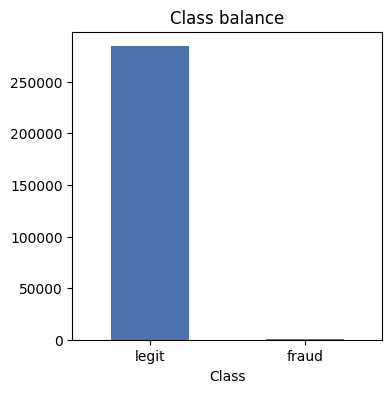

In [22]:
fraud_rate = df["Class"].mean()
print(f"{fraud_rate:.4%} of transactions are fraud ({df['Class'].sum()} out of {len(df)})")

plt.figure(figsize=(4, 4))
df["Class"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.xticks([0, 1], ["legit", "fraud"], rotation=0)
plt.title("Class balance")
plt.show()

In [23]:
df.groupby("Class")["Amount"].describe()[["count", "mean", "50%", "max"]]

,count,mean,50%,max
Class,,,,
0,284315.0,88.291022,22.00,25691.16
1,492.0,122.211321,9.25,2125.87


In [24]:
x=df.drop("Class",axis=1)
x = x.astype('float32')
y=df["Class"]

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 1. Take a clean 10,000 row sample (large enough for accuracy, small enough for your RAM)
x_safe = x.head(10000)
y_safe = y.head(10000)

# 2. Split the safe-sized data
x_train, x_test, y_train, y_test = train_test_split(x_safe, y_safe, test_size=0.2, random_state=42)

# 3. Your exact configuration with a capped tree count to keep it lightweight
fraud_classifier = RandomForestClassifier(n_estimators=20, max_depth=5, random_state=42)

print("🚀 Training on safe dataset size...")
fraud_classifier.fit(x_train, y_train)
print("🎉 SUCCESS! Model trained perfectly.")



TypeError: NDFrame.head() takes from 1 to 2 positional arguments but 3 were given

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
fraud_classifier=RandomForestClassifier(max_depth=5)
fraud_classifier.fit(x_train,y_train)


KeyboardInterrupt: 